# **INF01017 - Aprendizado de Máquina - INF/UFRGS**
#### *Profa. Mariana Recamonde Mendoza*

## Trabalho Prático Final — Parte 1 (T1): Caracterização do problema e *spot-checking* de algoritmos

### Detector de Ataques Cardíacos

**Integrantes:** Gabriel Pieruccini Knopp, Vítor Santana Feijó

**Dataset:** [Health care: Data set on Heart attack possibility (Kaggle)](https://www.kaggle.com/datasets/nareshbhat/health-care-data-set-on-heart-attack-possibility)

---

**Roteiro do notebook**

1. Definição do problema
2. Configuração do ambiente
3. Carregamento dos dados
4. Análise exploratória dos dados (EDA)
5. Pré-processamento dos dados *(próxima etapa)*
6. Definição da abordagem, dos algoritmos e da estratégia de avaliação *(próxima etapa)*
7. *Spot-checking* de algoritmos *(próxima etapa)*
8. Sumarização dos resultados e seleção de modelos para o T2 *(próxima etapa)*

# 1. Definição do problema

Nosso trabalho tem como objetivo desenvolver um modelo baseado em Aprendizado de Máquina para **prever a tendência de ataque cardíaco de um paciente**, representada pela **presença de doença cardíaca** (estreitamento superior a 50% do diâmetro de uma artéria coronária principal), a partir de um conjunto de características clínicas e de exames (idade, sexo, tipo de dor no peito, pressão arterial, colesterol, resultados de eletrocardiograma e de teste de esforço, entre outros).

Para tanto, utilizamos o conjunto de dados *Health care: Data set on Heart attack possibility*, disponível no [Kaggle](https://www.kaggle.com/datasets/nareshbhat/health-care-data-set-on-heart-attack-possibility). Ele é uma versão recodificada da base *Cleveland* do [UCI Heart Disease](https://archive.ics.uci.edu/dataset/45/heart+disease), com 303 registros e 13 atributos preditivos.

**Pergunta de pesquisa:** *é possível distinguir, com bom desempenho, pacientes com e sem doença cardíaca usando apenas esses 13 atributos clínicos? Quais famílias de algoritmos são mais promissoras para essa tarefa?*

Como o atributo-alvo (`target`) é **binário**, trata-se de um problema de **classificação binária**.

### Dicionário de dados

O significado dos códigos abaixo foi **verificado na Seção 4.3**, comparando cada registro com a base original da UCI — em alguns atributos ele difere da descrição publicada no Kaggle.

| Atributo | Descrição | Natureza | Códigos |
|---|---|---|---|
| `age` | Idade (anos) | Numérico | — |
| `sex` | Sexo | Binário | 0 = feminino; 1 = masculino |
| `cp` | Tipo de dor no peito | Categórico nominal | 0 = assintomática; 1 = angina atípica; 2 = dor não anginosa; 3 = angina típica |
| `trestbps` | Pressão arterial em repouso (mm Hg) | Numérico | — |
| `chol` | Colesterol sérico (mg/dl) | Numérico | — |
| `fbs` | Glicemia em jejum > 120 mg/dl | Binário | 0 = não; 1 = sim |
| `restecg` | Eletrocardiograma em repouso | Categórico nominal | 0 = hipertrofia ventricular esquerda; 1 = normal; 2 = anormalidade de onda ST-T |
| `thalach` | Frequência cardíaca máxima atingida (bpm) | Numérico | — |
| `exang` | Angina induzida por exercício | Binário | 0 = não; 1 = sim |
| `oldpeak` | Depressão do segmento ST induzida por exercício em relação ao repouso | Numérico | ≥ 0 |
| `slope` | Inclinação do segmento ST no pico do exercício | Categórico nominal | 0 = descendente; 1 = plana; 2 = ascendente |
| `ca` | Número de vasos principais coloridos por fluoroscopia | Discreto ordinal | 0 a 3 |
| `thal` | Cintilografia com tálio | Categórico nominal | 1 = defeito fixo; 2 = normal; 3 = defeito reversível |
| `target` | Diagnóstico de doença cardíaca | **Alvo** (binário) | 0 = com doença; 1 = sem doença |

> Observação: embora **todos** os atributos estejam armazenados como números, vários deles (`cp`, `restecg`, `slope`, `thal`) são **códigos de categorias**, sem relação de ordem ou distância entre os valores.

# 2. Configuração do ambiente

Bibliotecas principais: `pandas`, `numpy`, `matplotlib`, `seaborn` e `scikit-learn` (todas já disponíveis no Google Colab).

In [1]:
## Carregando as bibliotecas básicas necessárias
# A primeira linha é incluída para gerar os gráficos logo abaixo dos comandos de plot
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif

import warnings
warnings.filterwarnings("ignore")

## Semente única para todos os processos aleatórios (reprodutibilidade dos experimentos)
RANDOM_STATE = 42

## Configuração visual dos gráficos
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "grid.color": "#e1e0d9",
})

COR_PRINCIPAL = "#2a78d6"              # gráficos de uma única série
COR_ALERTA = "#d03b3b"                 # destaca o que exige atenção no pré-processamento
CORES_CLASSE = {0: "#2a78d6", 1: "#eb6834"}
NOMES_CLASSE = {0: "0 – com doença", 1: "1 – sem doença"}

In [2]:
def rotular_barras(ax, fmt="{:.0f}", sufixos=None, horizontal=False):
    """Escreve o valor de cada barra ao lado/acima dela (rótulos seletivos, sem poluir o gráfico)."""
    for i, barra in enumerate(ax.patches):
        valor = barra.get_width() if horizontal else barra.get_height()
        if np.isnan(valor):
            continue
        texto = fmt.format(valor) + (sufixos[i] if sufixos is not None else "")
        if horizontal:
            ax.annotate(texto, (valor, barra.get_y() + barra.get_height() / 2),
                        xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
        else:
            ax.annotate(texto, (barra.get_x() + barra.get_width() / 2, valor),
                        xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)


def cores_por_alerta(valores, condicao):
    """Retorna uma lista de cores: vermelho onde a condição é verdadeira, azul nos demais."""
    return [COR_ALERTA if c else COR_PRINCIPAL for c in condicao(np.asarray(valores))]


def legenda_alerta(ax, texto_alerta, texto_ok="sem problema", loc="lower right"):
    """Legenda das cores de alerta; `ax` pode ser um eixo ou a figura inteira."""
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=COR_ALERTA, label=texto_alerta),
                       Patch(color=COR_PRINCIPAL, label=texto_ok)], loc=loc, fontsize=9)

# 3. Carregamento dos dados

O arquivo `heart.csv` (idêntico ao disponibilizado no Kaggle) está versionado no repositório do grupo no GitHub. Assim, o notebook funciona tanto localmente quanto no Google Colab, sem necessidade de upload manual ou de credenciais do Kaggle.

In [3]:
## Carregando os dados
# encoding="utf-8-sig" remove o BOM presente no início do arquivo (senão a 1ª coluna viria como "﻿age")
URL_DADOS = "https://raw.githubusercontent.com/vitorsfeijo/Trabalho_ML/main/heart.csv"

try:
    df_original = pd.read_csv("heart.csv", encoding="utf-8-sig")   # execução local
except FileNotFoundError:
    df_original = pd.read_csv(URL_DADOS, encoding="utf-8-sig")     # execução no Google Colab

# Visualização inicial
df_original.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


# 4. Análise exploratória dos dados (EDA)

A EDA foi organizada em duas fases, para **evitar vazamento de informação (*data leakage*)** do conjunto de teste para as decisões de modelagem:

| Fase | Dados usados | O que é feito |
|---|---|---|
| **Antes da divisão** (4.1 – 4.5) | Conjunto completo | Apenas caracterização estrutural (dimensões, tipos, faltantes, duplicatas, domínio dos valores, distribuição do alvo) e **limpeza determinística**, que não aprende nenhuma estatística dos dados. |
| **Divisão treino/teste** (4.6) | — | Holdout estratificado 80/20 com semente fixa. O teste fica reservado para a avaliação final. |
| **Depois da divisão** (4.7 – 4.13) | **Somente treino** | Relações com o alvo, correlações, escalas, outliers, faltantes e relevância — tudo o que embasa decisões de pré-processamento. Quando uma transformação é ilustrada, ela é **ajustada no treino** e apenas *aplicada* ao teste. |

Nos gráficos de diagnóstico, **vermelho** indica o que requer atenção no pré-processamento.

## 4.1. Visão geral: quantidade e tipos de atributos

In [4]:
print("===== VISÃO GERAL DO DATASET =====")
print(f"Número de instâncias: {df_original.shape[0]}")
print(f"Número de atributos (incluindo o alvo): {df_original.shape[1]}")
print()
df_original.info()

===== VISÃO GERAL DO DATASET =====
Número de instâncias: 303
Número de atributos (incluindo o alvo): 14

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [5]:
## Agrupamento dos atributos segundo sua natureza (dicionário de dados da Seção 1).
## Atenção: todos estão armazenados como inteiros/reais, mas nem todos são quantitativos.
ALVO = "target"
ATR_CONTINUOS = ["age", "trestbps", "chol", "thalach", "oldpeak"]   # numéricos
ATR_BINARIOS = ["sex", "fbs", "exang"]
ATR_NOMINAIS = ["cp", "restecg", "slope", "thal"]                    # categorias codificadas como inteiros
ATR_ORDINAIS = ["ca"]                                                # contagem de vasos (0 a 3)
ATR_DISCRETOS = ATR_BINARIOS + ATR_NOMINAIS + ATR_ORDINAIS

natureza = {**{c: "numérico" for c in ATR_CONTINUOS},
            **{c: "binário" for c in ATR_BINARIOS},
            **{c: "categórico nominal" for c in ATR_NOMINAIS},
            **{c: "discreto ordinal" for c in ATR_ORDINAIS},
            ALVO: "alvo (binário)"}

resumo_tipos = pd.DataFrame({
    "tipo armazenado": df_original.dtypes.astype(str),
    "natureza": pd.Series(natureza),
    "valores distintos": df_original.nunique(),
    "mínimo": df_original.min(),
    "máximo": df_original.max(),
})
display(resumo_tipos)
print(resumo_tipos["natureza"].value_counts().to_string())

,tipo armazenado,natureza,valores distintos,mínimo,máximo
age,int64,numérico,41,29.0,77.0
ca,int64,discreto ordinal,5,0.0,4.0
chol,int64,numérico,152,126.0,564.0
cp,int64,categórico nominal,4,0.0,3.0
exang,int64,binário,2,0.0,1.0
fbs,int64,binário,2,0.0,1.0
oldpeak,float64,numérico,40,0.0,6.2
restecg,int64,categórico nominal,3,0.0,2.0
sex,int64,binário,2,0.0,1.0
slope,int64,categórico nominal,3,0.0,2.0


natureza
numérico              5
categórico nominal    4
binário               3
discreto ordinal      1
alvo (binário)        1


In [6]:
## Estatísticas descritivas de todos os atributos
df_original.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.37,9.08,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.97,1.03,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.62,17.54,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.26,51.83,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.53,0.53,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.65,22.91,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


**Observações:**
- São **303 instâncias** e **13 atributos preditivos + 1 alvo**, todos armazenados como numéricos (`int64`, exceto `oldpeak`, que é `float64`).
- Apenas 5 atributos são de fato quantitativos contínuos (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`); 3 são binários; `ca` é uma contagem; e 4 (`cp`, `restecg`, `slope`, `thal`) são **categorias nominais codificadas como inteiros**.
- As magnitudes são muito diferentes entre atributos (ex.: `chol` vai até centenas, `oldpeak` fica entre 0 e ~6) — indício de necessidade de normalização (Seção 4.9).
- Os valores máximos de `ca` (4) e o mínimo de `thal` (0) chamam atenção — investigados na Seção 4.3.

## 4.2. Valores faltantes e instâncias duplicadas

In [7]:
## Verifica se existem valores faltantes (missing)
print("Valores faltantes (NaN) por atributo:")
print(df_original.isnull().sum().to_string())
print(f"\nTotal de valores faltantes: {df_original.isnull().sum().sum()}")

## Verifica instâncias duplicadas (todas as colunas iguais)
n_duplicadas = df_original.duplicated().sum()
print(f"\nInstâncias duplicadas: {n_duplicadas}")
display(df_original[df_original.duplicated(keep=False)])

Valores faltantes (NaN) por atributo:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0

Total de valores faltantes: 0

Instâncias duplicadas: 1


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1


Não há valores `NaN` explícitos, mas existe **1 instância duplicada** (linhas 163 e 164 idênticas em todos os 14 atributos). Em uma base de 303 pacientes isso é muito provavelmente um erro de registro (confirmado na Seção 4.3). Além de enviesar levemente as estatísticas, uma duplicata é uma fonte direta de *data leakage*: se uma cópia cair no treino e a outra no teste, o modelo é avaliado em um exemplo que já "viu". Por isso, ela será removida **antes** da divisão treino/teste (Seção 4.5).

## 4.3. Consistência: valores fora do domínio esperado

A descrição do Kaggle informa `ca` como *"number of major vessels (0-3)"* e `thal` como *"0 = normal; 1 = fixed defect; 2 = reversable defect"*. Começamos comparando os valores observados com esses domínios. Para os atributos numéricos, usamos faixas fisiologicamente plausíveis e bem amplas, apenas para detectar erros grosseiros de digitação.

In [8]:
## Distribuição dos valores dos atributos com códigos suspeitos
print("ca:  ", df_original["ca"].value_counts().sort_index().to_dict())
print("thal:", df_original["thal"].value_counts().sort_index().to_dict())

ca:   {0: 175, 1: 65, 2: 38, 3: 20, 4: 5}
thal: {0: 2, 1: 18, 2: 166, 3: 117}


Os valores de `thal` **não batem com a descrição do Kaggle**: aparecem os códigos 1, 2 e **3** (este último em 117 pacientes), e o código 0 ("normal", segundo a descrição) aparece em apenas 2. Se a descrição estivesse correta, o código 3 — usado por mais de um terço da base — seria inválido, o que é implausível. Para resolver a dúvida com evidência, comparamos **cada registro** com a base original *Cleveland* da UCI, da qual esta versão deriva. A base da UCI marca valores ausentes com `?` e usa outra codificação (ex.: `thal` ∈ {3, 6, 7}; `num` = 0 para estreitamento < 50%, sem doença).

In [9]:
## Base original (UCI Heart Disease — Cleveland, 303 registros), com "?" representando valores ausentes.
## Cópia fiel do arquivo da UCI (licença CC BY 4.0), versionada no repositório para não depender do servidor
## da UCI. Original: https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data
URL_UCI = "https://raw.githubusercontent.com/vitorsfeijo/Trabalho_ML/main/processed.cleveland.data"
colunas_uci = list(df_original.columns[:-1]) + ["num"]

try:
    df_uci = pd.read_csv("processed.cleveland.data", header=None, names=colunas_uci, na_values="?")
except FileNotFoundError:
    df_uci = pd.read_csv(URL_UCI, header=None, names=colunas_uci, na_values="?")
print("Valores ausentes ('?') na base da UCI:", df_uci.isnull().sum()[lambda s: s > 0].to_dict())

## Casamento registro a registro pelos atributos contínuos + sexo (combinação que identifica cada paciente)
chave = ["age", "sex", "trestbps", "chol", "thalach", "oldpeak"]
casados = (df_original.astype({c: float for c in chave}).reset_index(names="id_kaggle")
           .merge(df_uci.astype({c: float for c in chave}).reset_index(names="id_uci"),
                  on=chave, suffixes=("", "_uci")))
print(f"Registros do Kaggle encontrados na UCI: {casados['id_kaggle'].nunique()} de {len(df_original)}")

## Correspondência entre os códigos do Kaggle e os da UCI ("?" = ausente na UCI)
print("\nCódigo no Kaggle → código na UCI:")
for col in ["cp", "restecg", "slope", "ca", "thal"]:
    mapa = casados.groupby(col)[col + "_uci"].agg(lambda s: "?" if s.isna().all() else f"{s.iloc[0]:g}")
    print(f"  {col:8s}", mapa.to_dict())

## Alvo do Kaggle × diagnóstico original da UCI
display(pd.crosstab(casados[ALVO], casados["num"].gt(0).map({False: "num = 0 (sem doença)",
                                                             True: "num > 0 (com doença)"}),
                    rownames=["target (Kaggle)"], colnames=["diagnóstico (UCI)"]))

## A duplicata: dois registros do Kaggle correspondem ao MESMO paciente da UCI
display(casados[casados.duplicated("id_uci", keep=False)][["id_kaggle", "id_uci"]])
print(f"Pacientes da UCI ausentes no Kaggle: {len(df_uci) - casados['id_uci'].nunique()}")

Valores ausentes ('?') na base da UCI: {'ca': 4, 'thal': 2}
Registros do Kaggle encontrados na UCI: 303 de 303

Código no Kaggle → código na UCI:
  cp       {0: '4', 1: '2', 2: '3', 3: '1'}
  restecg  {0: '2', 1: '0', 2: '1'}
  slope    {0: '3', 1: '2', 2: '1'}
  ca       {0: '0', 1: '1', 2: '2', 3: '3', 4: '?'}
  thal     {0: '?', 1: '6', 2: '3', 3: '7'}


diagnóstico (UCI),num = 0 (sem doença),num > 0 (com doença)
target (Kaggle),,
0,0,138
1,165,0


,id_kaggle,id_uci
163,163,302
164,164,302


Pacientes da UCI ausentes no Kaggle: 1


**Resultado da verificação** — todos os 303 registros do Kaggle têm correspondente na UCI, e cada código mapeia para exatamente um código original:

| Atributo | Significado real dos códigos do Kaggle | Correção necessária? |
|---|---|---|
| `ca` | 0–3 = número de vasos (idênticos à UCI); **4 = valor ausente** (`?` na UCI) | **Sim**: `ca = 4` (4 pacientes + a duplicata) |
| `thal` | **0 = valor ausente** (`?` na UCI); 1 = defeito fixo; 2 = normal; 3 = defeito reversível | **Sim**: `thal = 0` (2 pacientes) |
| `cp`, `restecg`, `slope` | Códigos válidos, apenas **permutados** em relação à UCI (ver dicionário de dados) | Não (serão tratados como categorias) |
| `target` | 1 = sem doença (`num = 0`); 0 = com doença (`num > 0`) | Não (só afeta a interpretação) |

Conclusões:
- A descrição do `thal` publicada no Kaggle está **incorreta**: "normal" é o código 2 (166 pacientes), e o código 0 não é uma categoria, mas a marcação de **valor ausente**. O mesmo ocorre com `ca = 4`. Esses números coincidem exatamente com os valores ausentes da base original (4 em `ca` e 2 em `thal`). **Somente essas 6 instâncias precisam de correção**; nenhum outro atributo tem valores fora do domínio.
- A **duplicata** é um artefato da versão do Kaggle: um paciente da UCI foi copiado duas vezes, enquanto outro paciente original ficou de fora. A remoção é, portanto, justificada.
- O alvo tem o sentido **oposto** ao da descrição do Kaggle ("1 = more chance of heart attack"): `target = 1` corresponde aos pacientes **sem** doença cardíaca. Isso não muda a modelagem (o problema continua sendo de classificação binária), mas é fundamental para interpretar os resultados.

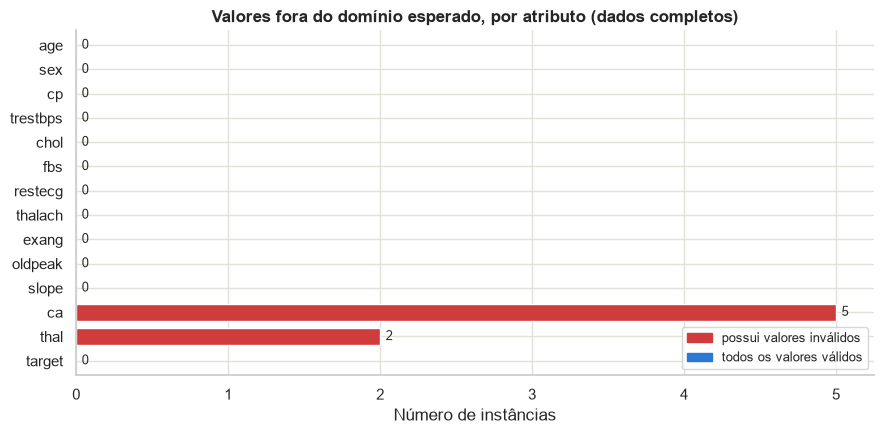

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
48,53,0,2,128,216,0,0,115,0,0.0,2,0,0,1
92,52,1,2,138,223,0,1,169,0,0.0,2,4,2,1
158,58,1,1,125,220,0,1,144,0,0.4,1,4,3,1
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
251,43,1,0,132,247,1,0,143,1,0.1,1,4,3,0
281,52,1,0,128,204,1,1,156,1,1.0,1,0,0,0


In [10]:
## Domínio esperado de cada atributo discreto (codificação real, verificada acima)
DOMINIO_ESPERADO = {
    "sex": {0, 1}, "fbs": {0, 1}, "exang": {0, 1},
    "cp": {0, 1, 2, 3}, "restecg": {0, 1, 2}, "slope": {0, 1, 2},
    "ca": {0, 1, 2, 3},     # número de vasos principais: 0 a 3
    "thal": {1, 2, 3},      # 0 marca valor ausente
    "target": {0, 1},
}
## Faixas plausíveis (amplas) para os atributos numéricos
FAIXA_PLAUSIVEL = {
    "age": (18, 100), "trestbps": (70, 250), "chol": (100, 700),
    "thalach": (60, 220), "oldpeak": (0, 10),
}

fora_dominio = {}
for col, valores in DOMINIO_ESPERADO.items():
    fora_dominio[col] = (~df_original[col].isin(valores)).sum()
for col, (minimo, maximo) in FAIXA_PLAUSIVEL.items():
    fora_dominio[col] = (~df_original[col].between(minimo, maximo)).sum()

fora_dominio = pd.Series(fora_dominio)[df_original.columns]

fig, ax = plt.subplots(figsize=(9, 4.5))
fora_dominio.plot.barh(ax=ax, color=cores_por_alerta(fora_dominio, lambda v: v > 0), width=0.7)
rotular_barras(ax, horizontal=True)
ax.invert_yaxis()
ax.set_title("Valores fora do domínio esperado, por atributo (dados completos)")
ax.set_xlabel("Número de instâncias")
legenda_alerta(ax, "possui valores inválidos", "todos os valores válidos")
plt.tight_layout()
plt.show()

display(df_original[(df_original["ca"] == 4) | (df_original["thal"] == 0)])

## 4.4. Distribuição do atributo-alvo

        instâncias  proporção
target                       
0              138      0.455
1              165      0.545

Razão de desbalanceamento (classe majoritária / minoritária): 1.20


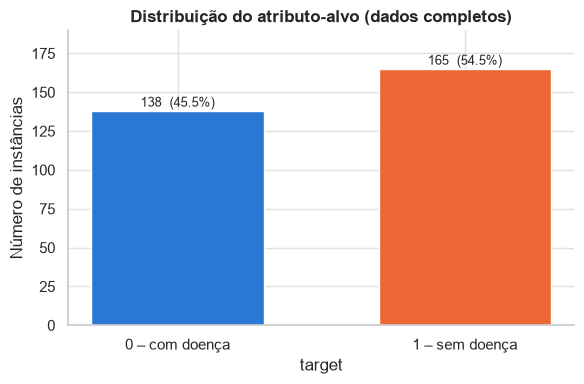

In [11]:
## Distribuição do atributo alvo
contagem_alvo = df_original[ALVO].value_counts().sort_index()
proporcao_alvo = df_original[ALVO].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"instâncias": contagem_alvo, "proporção": proporcao_alvo.round(3)}))
print(f"\nRazão de desbalanceamento (classe majoritária / minoritária): "
      f"{contagem_alvo.max() / contagem_alvo.min():.2f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([NOMES_CLASSE[c] for c in contagem_alvo.index], contagem_alvo.values,
       color=[CORES_CLASSE[c] for c in contagem_alvo.index], width=0.6)
rotular_barras(ax, sufixos=[f"  ({p:.1%})" for p in proporcao_alvo.values])
ax.set_title("Distribuição do atributo-alvo (dados completos)")
ax.set_xlabel("target")
ax.set_ylabel("Número de instâncias")
ax.set_ylim(0, contagem_alvo.max() * 1.15)
plt.tight_layout()
plt.show()

As classes estão **levemente desbalanceadas**: ~54% da classe 1 (sem doença) e ~46% da classe 0 (com doença), razão ≈ 1,2. Esse grau de desbalanceamento é pequeno e **não exige técnicas de balanceamento** (como SMOTE ou *undersampling*) nem ponderação de classes. Ainda assim, usaremos **divisões estratificadas** (para preservar essa proporção em treino, teste e em cada *fold*) e métricas complementares à acurácia.

## 4.5. Limpeza determinística (antes da divisão)

A verificação da Seção 4.3 confirmou que **a correção é necessária**. Aplicamos aqui apenas correções que **não dependem de nenhuma estatística aprendida dos dados** — são regras fixas, aplicadas linha a linha, que dariam o mesmo resultado se fossem feitas depois da divisão. Por isso não há vazamento de informação:

1. **Remoção da instância duplicada** — feita antes da divisão justamente para impedir que as duas cópias fiquem uma no treino e outra no teste.
2. **Marcação dos códigos de ausência como faltantes** (`ca = 4` → `NaN`; `thal = 0` → `NaN`).

A **imputação** desses valores (que *aprende* uma estatística, como a moda) **não** é feita aqui: ela ficará dentro do *pipeline* de pré-processamento e será ajustada somente nos dados de treino (Seção 4.11).

In [12]:
## 1) Remoção da instância duplicada (mantém a primeira ocorrência)
df = df_original.drop_duplicates(keep="first").reset_index(drop=True)
print(f"Instâncias: {len(df_original)} → {len(df)} (removida(s) {len(df_original) - len(df)} duplicata(s))")

## 2) Códigos fora do domínio passam a ser valores faltantes explícitos
for col in ["ca", "thal"]:
    df[col] = df[col].where(df[col].isin(DOMINIO_ESPERADO[col]))

print("\nValores faltantes após a marcação:")
print(df.isnull().sum()[lambda s: s > 0].to_string())
print(f"Instâncias com ao menos um valor faltante: {df.isnull().any(axis=1).sum()} "
      f"({df.isnull().any(axis=1).mean():.1%} da base)")
print("\nDistribuição do alvo após a limpeza:", df[ALVO].value_counts().sort_index().to_dict())

Instâncias: 303 → 302 (removida(s) 1 duplicata(s))

Valores faltantes após a marcação:
ca      4
thal    2
Instâncias com ao menos um valor faltante: 6 (2.0% da base)

Distribuição do alvo após a limpeza: {0: 138, 1: 164}


## 4.6. Divisão dos dados em treino e teste

Antes de qualquer análise que embase decisões de pré-processamento, reservamos **20% dos dados para teste**, com **estratificação pelo alvo** e semente fixa. O conjunto de teste simula dados nunca vistos e só será usado na avaliação final (T2). No *spot-checking*, os algoritmos serão comparados por validação cruzada **apenas sobre o conjunto de treino**, com o pré-processamento encapsulado em um `Pipeline` (ajustado dentro de cada *fold*).

Tamanho treino: (241, 13)
Tamanho teste:  (61, 13)


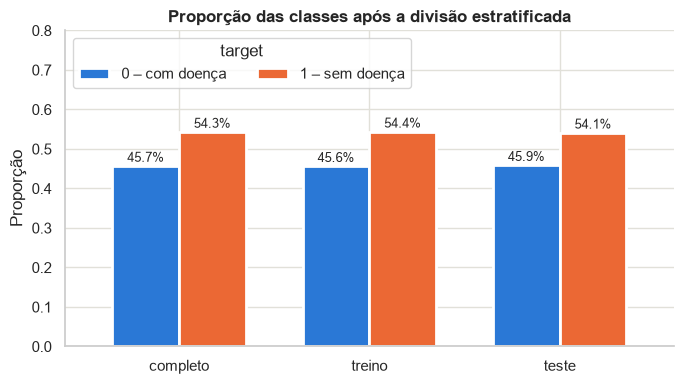

In [13]:
## Separando X (atributos) e y (alvo) para se adequar às funções do scikit-learn
X = df.drop(columns=ALVO)
y = df[ALVO]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

## DataFrame de treino (atributos + alvo) usado em toda a análise a partir daqui
df_train = X_train.assign(**{ALVO: y_train})

print("Tamanho treino:", X_train.shape)
print("Tamanho teste: ", X_test.shape)

proporcoes = pd.DataFrame({
    "completo": y.value_counts(normalize=True),
    "treino": y_train.value_counts(normalize=True),
    "teste": y_test.value_counts(normalize=True),
}).sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
proporcoes.T.rename(columns=NOMES_CLASSE).plot.bar(
    ax=ax, color=[CORES_CLASSE[0], CORES_CLASSE[1]], width=0.7, rot=0, edgecolor="white", linewidth=2)
rotular_barras(ax, fmt="{:.1%}")
ax.set_title("Proporção das classes após a divisão estratificada")
ax.set_ylabel("Proporção")
ax.set_ylim(0, 0.8)
ax.legend(title="target", loc="upper left", ncol=2)
plt.tight_layout()
plt.show()

## 4.7. Relação dos atributos com o alvo (somente treino)

### Atributos numéricos por classe

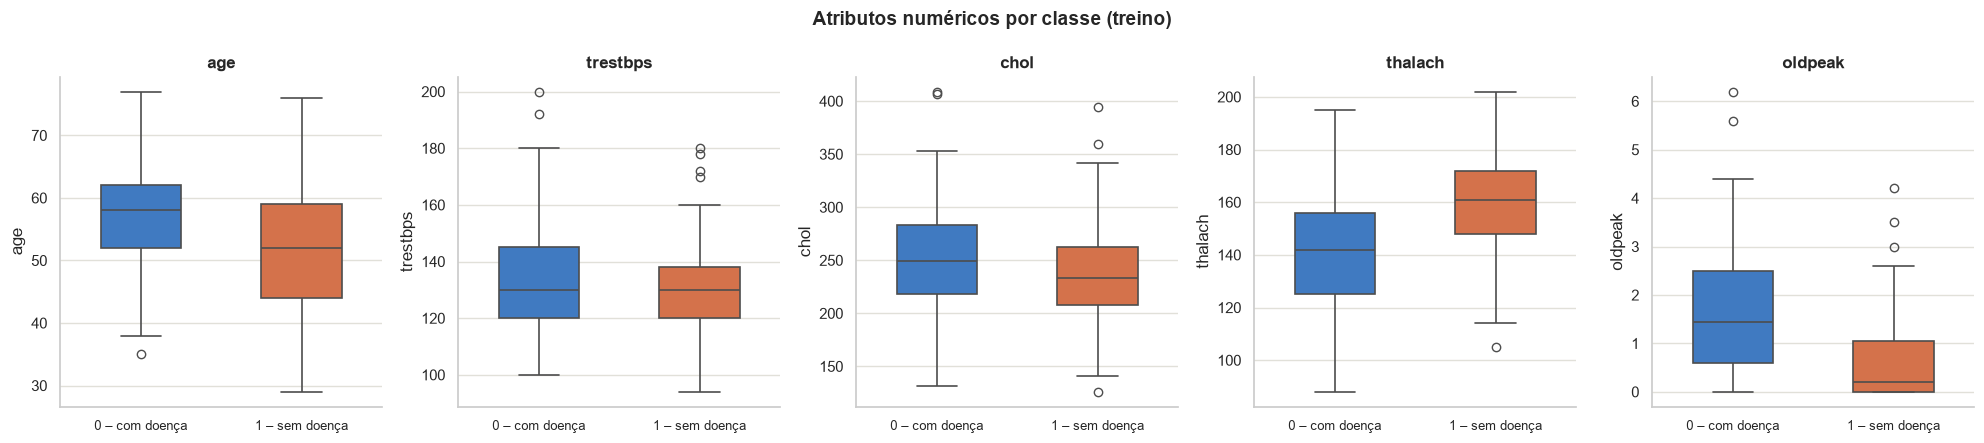

,age,trestbps,chol,thalach,oldpeak
target,,,,,
0 – com doença,56.45,134.41,252.14,140.00,1.66
1 – sem doença,52.56,128.96,237.72,158.53,0.58


In [14]:
## Boxplots de cada atributo numérico separados pela classe
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, col in zip(axes, ATR_CONTINUOS):
    sns.boxplot(data=df_train, x=ALVO, y=col, hue=ALVO, palette=CORES_CLASSE,
                legend=False, ax=ax, width=0.5, linewidth=1.2)
    ax.set_title(col)
    ax.set_xticks([0, 1], [NOMES_CLASSE[0], NOMES_CLASSE[1]], fontsize=9)
    ax.set_xlabel("")
fig.suptitle("Atributos numéricos por classe (treino)", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

## Médias por classe
df_train.groupby(ALVO)[ATR_CONTINUOS].mean().round(2).rename(index=NOMES_CLASSE)

### Atributos discretos por classe

Cada barra mostra, para um valor do atributo, a proporção de pacientes em cada classe. O número de instâncias de cada valor (`n`) aparece no eixo — barras com `n` pequeno são pouco confiáveis.

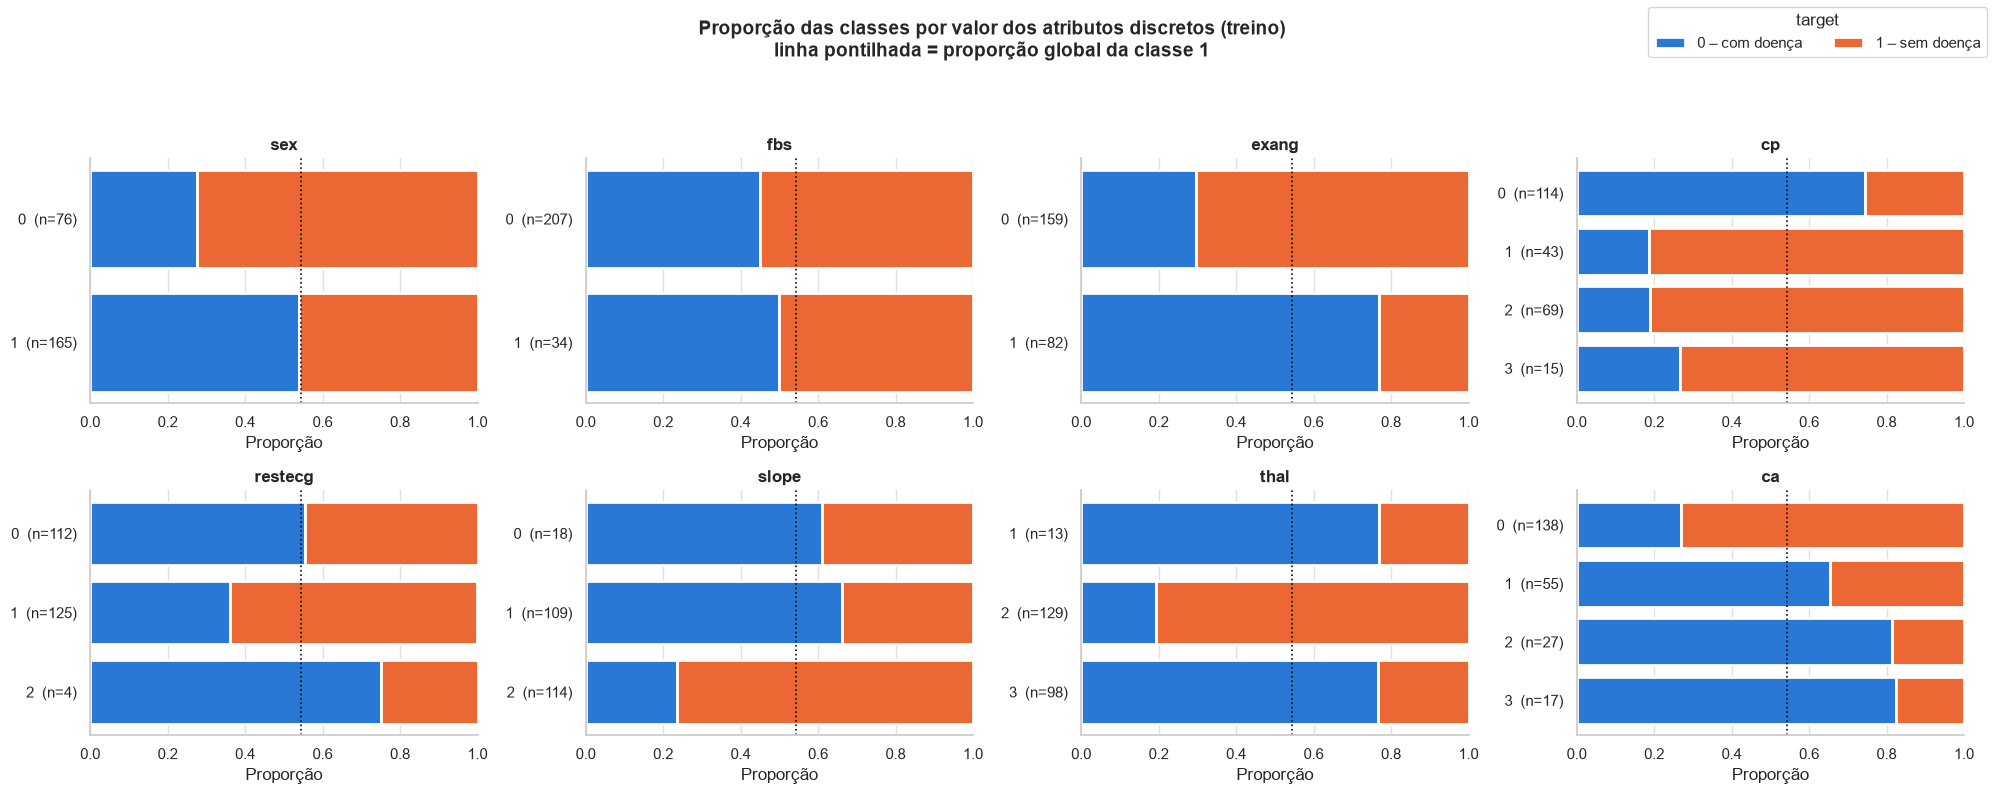

In [15]:
## Barras 100% empilhadas: proporção de cada classe dentro de cada valor do atributo
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flat, ATR_DISCRETOS):
    tabela = pd.crosstab(df_train[col], df_train[ALVO], normalize="index")
    n = df_train[col].value_counts().sort_index()
    rotulos = [f"{int(v)}  (n={n[v]})" for v in tabela.index]
    esquerda = np.zeros(len(tabela))
    for classe in [0, 1]:
        ax.barh(rotulos, tabela[classe], left=esquerda, color=CORES_CLASSE[classe],
                edgecolor="white", linewidth=2, label=NOMES_CLASSE[classe])
        esquerda += tabela[classe].values
    ax.axvline(y_train.mean(), color="#0b0b0b", linestyle=":", linewidth=1.2)
    ax.set_xlim(0, 1)
    ax.invert_yaxis()
    ax.set_title(col)
    ax.set_xlabel("Proporção")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, title="target", loc="upper right", ncol=2)
fig.suptitle("Proporção das classes por valor dos atributos discretos (treino)\n"
             "linha pontilhada = proporção global da classe 1", fontweight="bold", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**Padrões observados** (lembrando que a classe 0 é a dos pacientes **com doença**):
- Pacientes com doença têm, em média, **`thalach` mais baixo**, **`oldpeak` mais alto** e idade um pouco maior. `chol` e `trestbps` diferem pouco entre as classes.
- `cp`, `exang`, `ca`, `thal`, `slope` e `sex` mostram diferenças marcantes de proporção entre seus valores: dor no peito **assintomática** (`cp = 0`), angina induzida por exercício (`exang = 1`), mais vasos afetados (`ca` maior) e defeitos na cintilografia (`thal` = 1 ou 3) concentram os casos de doença. Esses padrões são **coerentes com a literatura clínica**, o que reforça a leitura correta do alvo feita na Seção 4.3. Já `fbs` praticamente não altera a proporção das classes.
- A relação de `cp`, `slope` e `thal` com o alvo **não é monotônica** nos códigos (ex.: em `cp`, o código 0 tem perfil oposto aos códigos 1, 2 e 3), o que confirma que tratá-los como números ordenados seria inadequado.
- Há categorias **raras**, como `restecg = 2`, com pouquíssimas instâncias.

## 4.8. Correlação entre atributos (somente treino)

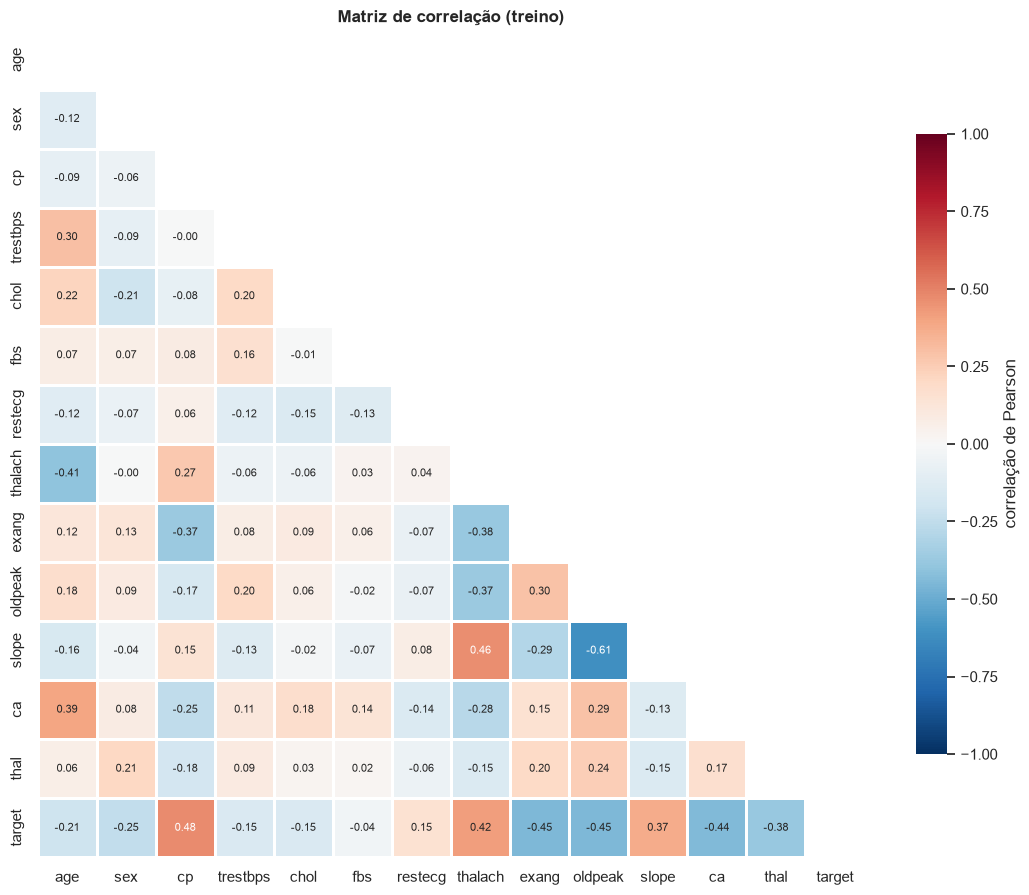

In [16]:
## Matriz de correlação de Pearson (triângulo inferior)
## Obs.: para os atributos nominais o coeficiente é apenas indicativo, pois seus códigos não têm ordem
correlacao = df_train.corr()
mascara = np.triu(np.ones_like(correlacao, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(correlacao, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, linewidths=1, linecolor="white", square=True,
            cbar_kws={"shrink": 0.75, "label": "correlação de Pearson"}, annot_kws={"size": 8}, ax=ax)
ax.grid(False)
ax.set_title("Matriz de correlação (treino)")
plt.tight_layout()
plt.show()

Nenhum par de atributos preditivos apresenta correlação muito alta (o maior valor absoluto fica em torno de 0,6, entre `oldpeak` e `slope`, o que é esperado, já que ambos descrevem o segmento ST no teste de esforço). Assim, **não há redundância forte** que justifique a remoção de atributos. As correlações mais fortes com o alvo envolvem `cp`, `thalach`, `exang`, `oldpeak`, `ca` e `thal`.

## 4.9. Escala dos atributos numéricos (necessidade de normalização)

,mínimo,máximo,amplitude,desvio padrão
chol,126.0,409.0,283.0,48.11
thalach,88.0,202.0,114.0,22.09
trestbps,94.0,200.0,106.0,17.99
age,29.0,77.0,48.0,9.22
oldpeak,0.0,6.2,6.2,1.21


A maior amplitude (chol) é 46x a menor (oldpeak).


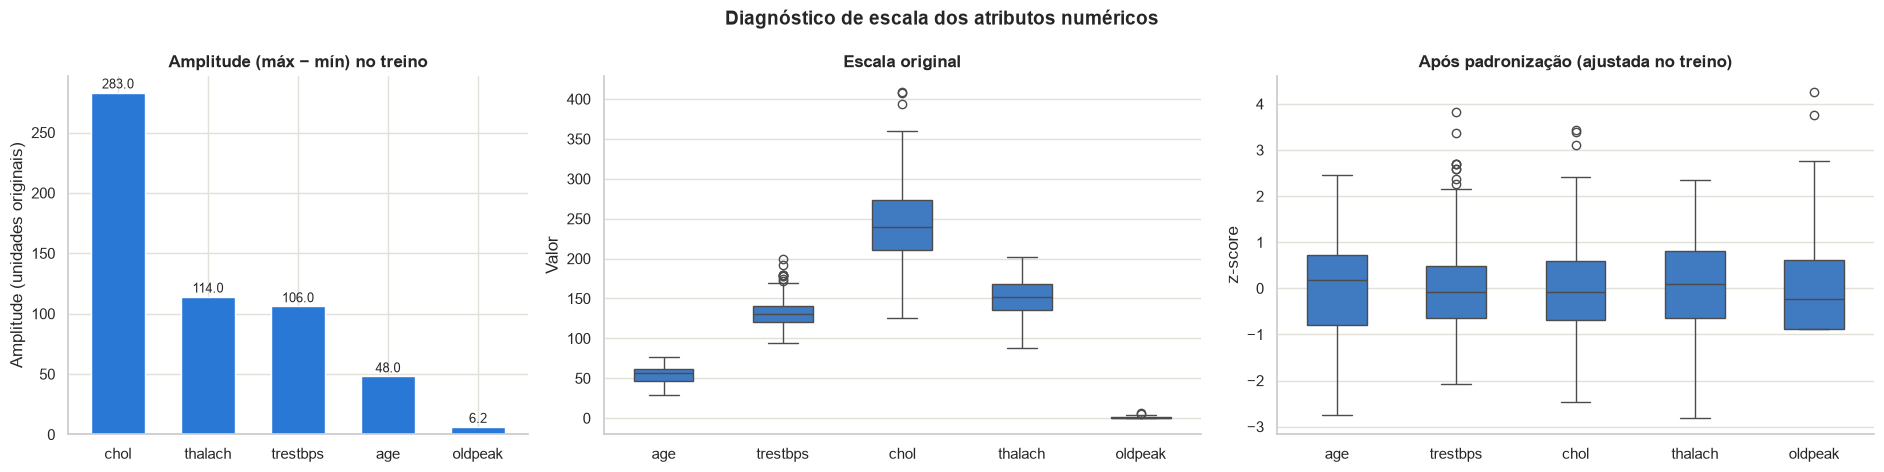

          média treino  média teste  desvio treino  desvio teste
age                0.0        0.043            1.0         0.905
trestbps          -0.0        0.043            1.0         0.878
chol               0.0        0.227            1.0         1.320
thalach           -0.0       -0.113            1.0         1.169
oldpeak           -0.0       -0.115            1.0         0.795


In [17]:
## Amplitude e desvio padrão de cada atributo numérico (treino)
escala = pd.DataFrame({
    "mínimo": X_train[ATR_CONTINUOS].min(),
    "máximo": X_train[ATR_CONTINUOS].max(),
    "amplitude": X_train[ATR_CONTINUOS].max() - X_train[ATR_CONTINUOS].min(),
    "desvio padrão": X_train[ATR_CONTINUOS].std(),
}).sort_values("amplitude", ascending=False)
display(escala.round(2))
razao_amplitude = escala["amplitude"].max() / escala["amplitude"].min()
print(f"A maior amplitude ({escala.index[0]}) é {razao_amplitude:.0f}x a menor ({escala.index[-1]}).")

## Padronização (z-score) AJUSTADA SOMENTE NO TREINO e aplicada ao treino e ao teste
scaler = StandardScaler().fit(X_train[ATR_CONTINUOS])
X_train_pad = pd.DataFrame(scaler.transform(X_train[ATR_CONTINUOS]), columns=ATR_CONTINUOS)
X_test_pad = pd.DataFrame(scaler.transform(X_test[ATR_CONTINUOS]), columns=ATR_CONTINUOS)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), gridspec_kw={"width_ratios": [1, 1.3, 1.3]})

escala["amplitude"].plot.bar(ax=axes[0], color=COR_PRINCIPAL, rot=0, width=0.6)
rotular_barras(axes[0], fmt="{:.1f}")
axes[0].set_title("Amplitude (máx − mín) no treino")
axes[0].set_ylabel("Amplitude (unidades originais)")

sns.boxplot(data=X_train[ATR_CONTINUOS], ax=axes[1], color=COR_PRINCIPAL, width=0.5)
axes[1].set_title("Escala original")
axes[1].set_ylabel("Valor")

sns.boxplot(data=X_train_pad, ax=axes[2], color=COR_PRINCIPAL, width=0.5)
axes[2].set_title("Após padronização (ajustada no treino)")
axes[2].set_ylabel("z-score")

fig.suptitle("Diagnóstico de escala dos atributos numéricos", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

## Conferência: no treino, média 0 e desvio 1 por construção; no teste, apenas próximos disso
print(pd.DataFrame({"média treino": X_train_pad.mean(), "média teste": X_test_pad.mean(),
                    "desvio treino": X_train_pad.std(ddof=0), "desvio teste": X_test_pad.std(ddof=0)}).round(3))

**Diagnóstico:** as escalas são muito heterogêneas — `chol` tem amplitude dezenas de vezes maior que `oldpeak`. Em algoritmos baseados em distância (KNN), em margens (SVM), em gradiente/regularização (Regressão Logística, Redes Neurais), atributos de maior amplitude dominariam o aprendizado de forma arbitrária. **É necessário normalizar**; a opção adotada é a padronização *z-score* (`StandardScaler`). Árvores de decisão e *ensembles* de árvores não são afetados pela escala.

Note que, no teste, as médias e desvios padronizados **não** são exatamente 0 e 1: isso é o comportamento correto, pois o *scaler* usa apenas parâmetros aprendidos no treino.

## 4.10. Outliers

,limite inferior,limite superior,outliers treino,outliers teste,% treino
age,26.0,82.0,0,0,0.0
trestbps,90.0,170.0,9,0,3.7
chol,118.0,366.0,3,2,1.2
thalach,88.0,216.0,0,1,0.0
oldpeak,-2.7,4.5,2,0,0.8


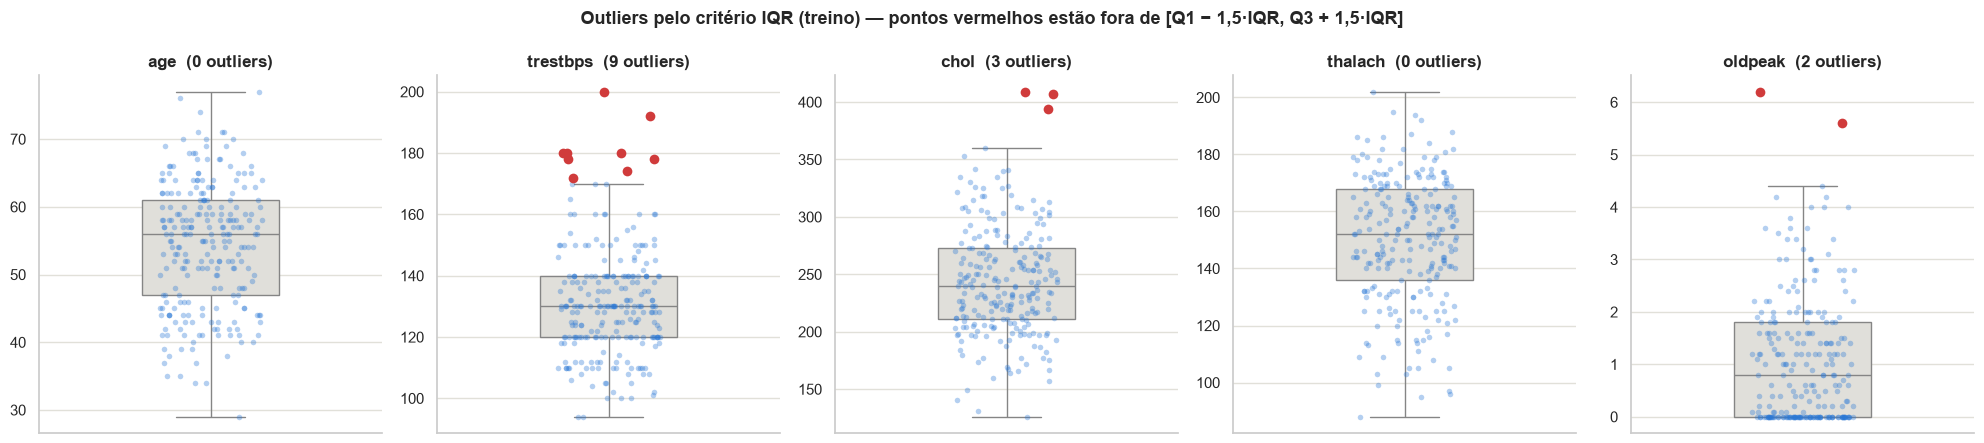

Valores considerados outliers no treino:
  trestbps: [172, 174, 178, 178, 180, 180, 180, 192, 200]
  chol: [394, 407, 409]
  oldpeak: [5.6, 6.2]


In [18]:
def limites_iqr(serie, k=1.5):
    """Limites de Tukey: [Q1 - k*IQR, Q3 + k*IQR]."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

## Limites calculados no TREINO e aplicados também ao teste
limites = {col: limites_iqr(X_train[col]) for col in ATR_CONTINUOS}
outliers = pd.DataFrame({
    "limite inferior": {c: l[0] for c, l in limites.items()},
    "limite superior": {c: l[1] for c, l in limites.items()},
    "outliers treino": {c: (~X_train[c].between(*l)).sum() for c, l in limites.items()},
    "outliers teste": {c: (~X_test[c].between(*l)).sum() for c, l in limites.items()},
})
outliers["% treino"] = (100 * outliers["outliers treino"] / len(X_train)).round(1)
display(outliers.round(2))

fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, col in zip(axes, ATR_CONTINUOS):
    inf, sup = limites[col]
    eh_outlier = ~X_train[col].between(inf, sup)
    sns.boxplot(y=X_train[col], ax=ax, color="#e1e0d9", width=0.4, showfliers=False)
    sns.stripplot(y=X_train[col][~eh_outlier], ax=ax, color=COR_PRINCIPAL, alpha=0.35, size=4, jitter=0.15)
    sns.stripplot(y=X_train[col][eh_outlier], ax=ax, color=COR_ALERTA, size=7, jitter=0.15)
    ax.set_title(f"{col}  ({eh_outlier.sum()} outliers)")
    ax.set_ylabel("")
fig.suptitle("Outliers pelo critério IQR (treino) — pontos vermelhos estão fora de [Q1 − 1,5·IQR, Q3 + 1,5·IQR]",
             fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

print("Valores considerados outliers no treino:")
for col in ATR_CONTINUOS:
    valores = sorted(X_train[col][~X_train[col].between(*limites[col])].tolist())
    if valores:
        print(f"  {col}: {valores}")

**Diagnóstico:** no treino há *outliers* estatísticos em `trestbps`, `chol` e `oldpeak` (poucos casos, menos de 4% por atributo); usando os mesmos limites, o teste ainda tem valores extremos em `chol` (incluindo o máximo da base, 564 mg/dl) e em `thalach`. Todos os valores são, porém, **clinicamente plausíveis** (ex.: pressão de 200 mm Hg ou colesterol acima de 400 mg/dl ocorrem em pacientes reais e podem ser justamente informativos para o problema). Como não são erros de registro (Seção 4.3) e a base é pequena, **a decisão sugerida é manter essas instâncias**. Caso algum modelo se mostre sensível a eles, uma alternativa no T2 é usar uma normalização robusta (`RobustScaler`).

## 4.11. Valores faltantes (após a marcação dos códigos de ausência)

,treino,teste,% treino
ca,4,0,1.7
thal,1,1,0.4


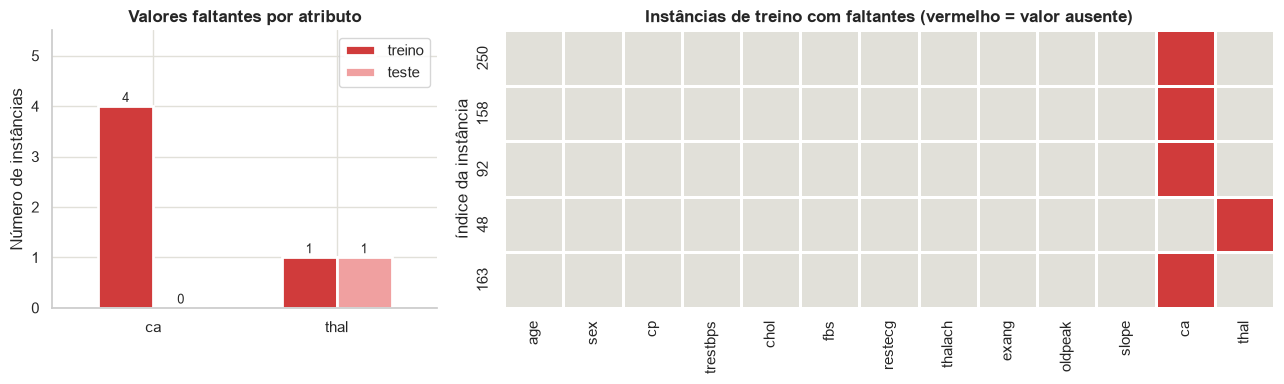

Moda no treino (valor a imputar): {'ca': 0, 'thal': 2}


In [19]:
## Quantidade de faltantes por atributo em treino e teste
faltantes = pd.DataFrame({"treino": X_train.isnull().sum(), "teste": X_test.isnull().sum()})
faltantes = faltantes[faltantes.sum(axis=1) > 0]
display(faltantes.assign(**{"% treino": (100 * faltantes["treino"] / len(X_train)).round(1)}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 2]})

faltantes.plot.bar(ax=axes[0], color=[COR_ALERTA, "#f0a0a0"], rot=0, width=0.6, edgecolor="white", linewidth=2)
rotular_barras(axes[0])
axes[0].set_title("Valores faltantes por atributo")
axes[0].set_ylabel("Número de instâncias")
axes[0].set_ylim(0, faltantes.values.max() + 1.5)

## Mapa das instâncias de treino com valores faltantes (linhas = instâncias, colunas = atributos)
linhas_com_nan = X_train[X_train.isnull().any(axis=1)]
sns.heatmap(linhas_com_nan.isnull(), cbar=False, cmap=["#e1e0d9", COR_ALERTA], linewidths=1,
            linecolor="white", ax=axes[1])
axes[1].set_title("Instâncias de treino com faltantes (vermelho = valor ausente)")
axes[1].set_ylabel("índice da instância")
plt.tight_layout()
plt.show()

## Valores que seriam usados numa imputação pela moda — calculados SOMENTE no treino
print("Moda no treino (valor a imputar):", {c: int(X_train[c].mode()[0]) for c in faltantes.index})

**Diagnóstico:** restam poucos valores faltantes (apenas em `ca` e `thal`, cerca de 2% das instâncias), sem nenhuma instância com mais de um valor ausente. Há duas opções razoáveis:

1. **Imputação pela moda** (`SimpleImputer(strategy="most_frequent")`), ajustada no treino — preserva todas as instâncias de uma base já pequena; **opção adotada**.
2. Remoção das 6 instâncias com faltantes — também aceitável dado o volume pequeno.

A imputação deve ficar **dentro do `Pipeline`**, para que a moda seja recalculada apenas com os dados de treino de cada *fold*.

## 4.12. Relevância dos atributos e redundância

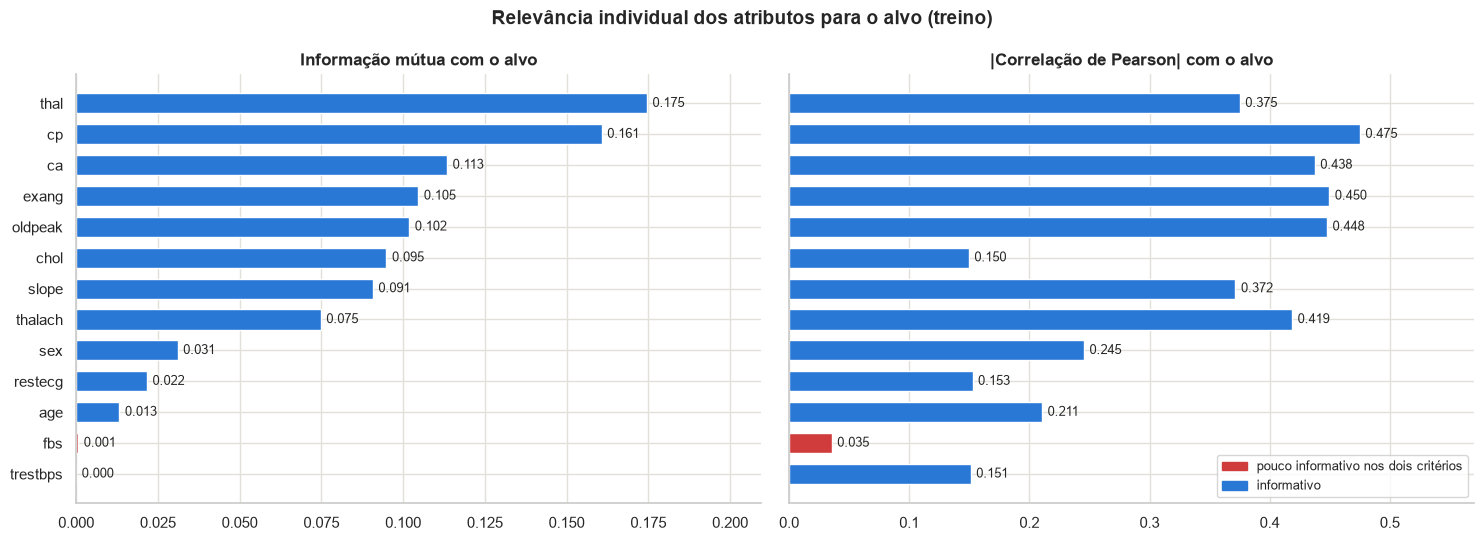

Atributos pouco informativos (individualmente): ['fbs']

Pares de atributos mais correlacionados (|r|):
oldpeak  slope      0.610
thalach  slope      0.463
age      thalach    0.406
         ca         0.392
thalach  exang      0.380


In [20]:
## Para a informação mútua, os faltantes são preenchidos TEMPORARIAMENTE com a moda do treino
X_train_mi = X_train.fillna(X_train.mode().iloc[0])
eh_discreto = [col in ATR_DISCRETOS for col in X_train_mi.columns]

informacao_mutua = pd.Series(
    mutual_info_classif(X_train_mi, y_train, discrete_features=eh_discreto, random_state=RANDOM_STATE),
    index=X_train_mi.columns).sort_values()
correlacao_alvo = df_train.corr()[ALVO].drop(ALVO).abs().reindex(informacao_mutua.index)

## Atributos pouco informativos pelos dois critérios (abaixo de 1/4 do valor máximo)
pouco_informativo = (informacao_mutua < 0.25 * informacao_mutua.max()) & (correlacao_alvo < 0.25 * correlacao_alvo.max())

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, serie, titulo in [(axes[0], informacao_mutua, "Informação mútua com o alvo"),
                          (axes[1], correlacao_alvo, "|Correlação de Pearson| com o alvo")]:
    ax.barh(serie.index, serie.values, color=cores_por_alerta(pouco_informativo, lambda v: v), height=0.65)
    rotular_barras(ax, fmt="{:.3f}", horizontal=True)
    ax.set_title(titulo)
    ax.set_xlim(0, serie.max() * 1.2)
legenda_alerta(axes[1], "pouco informativo nos dois critérios", "informativo", loc="lower right")
fig.suptitle("Relevância individual dos atributos para o alvo (treino)", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

print("Atributos pouco informativos (individualmente):", pouco_informativo[pouco_informativo].index.tolist())

## Pares de atributos preditivos mais correlacionados (redundância)
corr_atributos = X_train.corr().abs()
pares = (corr_atributos.where(np.triu(np.ones_like(corr_atributos, dtype=bool), k=1))
         .stack().sort_values(ascending=False))
print("\nPares de atributos mais correlacionados (|r|):")
print(pares.head(5).round(3).to_string())

**Diagnóstico:**
- `fbs` é **pouco informativo pelos dois critérios**; `trestbps`, `age` e `restecg` também têm baixa relevância em pelo menos um deles. Os critérios nem sempre concordam (ex.: `chol` tem correlação baixa, mas informação mútua moderada, o que sugere uma relação não linear). Além disso, informação mútua e correlação avaliam cada atributo **isoladamente** e não capturam interações. Como a base tem poucos atributos (13) e o *spot-checking* deve ser rápido e com configurações padrão, **a sugestão é manter todos os atributos** nesta etapa e deixar a seleção de atributos como possível refinamento no T2.
- Não há **redundância** forte (maior |r| ≈ 0,6, entre `oldpeak` e `slope`), portanto nenhum atributo precisa ser removido por multicolinearidade.

## 4.13. Síntese dos problemas identificados e ações propostas

In [21]:
## Valores usados na síntese
n_final = X_train.shape[1] - len(ATR_NOMINAIS) + sum(X_train[c].nunique() for c in ATR_NOMINAIS)
contagem_treino = y_train.value_counts()
razao_desbalanceamento = contagem_treino.max() / contagem_treino.min()

sintese = pd.DataFrame([
    ["Instância duplicada",
     f"{n_duplicadas} linha repetida (paciente da UCI copiado duas vezes)",
     "Removida antes da divisão (feito na Seção 4.5)"],
    ["Valores faltantes disfarçados",
     "ca = 4 e thal = 0 correspondem aos valores ausentes ('?') da base UCI original",
     "Marcados como NaN (feito); imputar pela moda do treino dentro do Pipeline"],
    ["Descrição dos códigos inconsistente",
     "thal e target diferem da descrição do Kaggle; cp, restecg e slope têm códigos permutados",
     "Nenhuma recodificação (categorias); usar o significado verificado na interpretação"],
    ["Escalas heterogêneas",
     f"amplitude de {escala.index[0]} é {razao_amplitude:.0f}x a de {escala.index[-1]}",
     "Padronização z-score (StandardScaler) ajustada no treino de cada fold"],
    ["Nominais codificados como inteiros",
     ", ".join(ATR_NOMINAIS) + " — relação não monotônica com o alvo",
     f"One-hot encoding ({X_train.shape[1]} → {n_final} colunas)"],
    ["Categorias raras",
     f"ex.: restecg = 2 com {(X_train['restecg'] == 2).sum()} instâncias no treino",
     "OneHotEncoder(handle_unknown='ignore'); agrupamento opcional no T2"],
    ["Outliers",
     ", ".join(f"{c} ({n})" for c, n in outliers["outliers treino"].items() if n > 0),
     "Manter (valores clinicamente plausíveis); RobustScaler opcional no T2"],
    ["Balanceamento das classes",
     f"razão {razao_desbalanceamento:.2f} (≈ {contagem_treino.max() / contagem_treino.sum():.0%} × "
     f"{contagem_treino.min() / contagem_treino.sum():.0%})",
     "Sem reamostragem; divisões estratificadas e métricas além da acurácia"],
    ["Atributos pouco informativos",
     ", ".join(pouco_informativo[pouco_informativo].index) + " (baixa MI e correlação)",
     "Manter no spot-checking; seleção de atributos opcional no T2"],
    ["Redundância",
     f"maior |r| = {pares.iloc[0]:.2f} ({pares.index[0][0]} × {pares.index[0][1]})",
     "Nenhuma remoção necessária"],
    ["Base pequena",
     f"{len(df)} instâncias ({len(X_train)} no treino)",
     "Validação cruzada estratificada repetida no treino (em vez de um único holdout)"],
], columns=["Problema", "Evidência", "Ação proposta"])

with pd.option_context("display.max_colwidth", None):
    display(sintese.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Problema,Evidência,Ação proposta
Instância duplicada,1 linha repetida (paciente da UCI copiado duas vezes),Removida antes da divisão (feito na Seção 4.5)
Valores faltantes disfarçados,ca = 4 e thal = 0 correspondem aos valores ausentes ('?') da base UCI original,Marcados como NaN (feito); imputar pela moda do treino dentro do Pipeline
Descrição dos códigos inconsistente,"thal e target diferem da descrição do Kaggle; cp, restecg e slope têm códigos permutados",Nenhuma recodificação (categorias); usar o significado verificado na interpretação
Escalas heterogêneas,amplitude de chol é 46x a de oldpeak,Padronização z-score (StandardScaler) ajustada no treino de cada fold
Nominais codificados como inteiros,"cp, restecg, slope, thal — relação não monotônica com o alvo",One-hot encoding (13 → 22 colunas)
Categorias raras,ex.: restecg = 2 com 4 instâncias no treino,OneHotEncoder(handle_unknown='ignore'); agrupamento opcional no T2
Outliers,"trestbps (9), chol (3), oldpeak (2)",Manter (valores clinicamente plausíveis); RobustScaler opcional no T2
Balanceamento das classes,razão 1.19 (≈ 54% × 46%),Sem reamostragem; divisões estratificadas e métricas além da acurácia
Atributos pouco informativos,fbs (baixa MI e correlação),Manter no spot-checking; seleção de atributos opcional no T2
Redundância,maior |r| = 0.61 (oldpeak × slope),Nenhuma remoção necessária


### Resumo da EDA

O conjunto de dados é pequeno (302 instâncias únicas, 13 atributos), está quase balanceado e não possui valores `NaN` explícitos. Os principais problemas encontrados são: **uma instância duplicada**, **valores faltantes codificados como valores fora do domínio** em `ca` e `thal` (confirmados pela comparação com a base original da UCI, que também revelou que o alvo tem o sentido oposto ao da descrição do Kaggle), **escalas muito diferentes entre os atributos numéricos** e **atributos categóricos nominais armazenados como inteiros**. *Outliers* e atributos de baixa relevância individual também foram identificados, mas não exigem tratamento obrigatório para o *spot-checking*.

As ações da tabela acima serão implementadas na próxima etapa por meio de um `Pipeline` do scikit-learn (imputação → *one-hot encoding* / padronização → classificador), garantindo que **todo ajuste de pré-processamento seja feito somente com dados de treino** de cada *fold*, sem vazamento de informação.

# 5. Pré-processamento dos dados

*(Próxima etapa — implementação do `Pipeline` com as ações definidas na Seção 4.13.)*

# 6. Definição da abordagem, dos algoritmos e da estratégia de avaliação

*(Próxima etapa.)*

# 7. *Spot-checking* de algoritmos

*(Próxima etapa.)*

# 8. Sumarização dos resultados e seleção de modelos para o T2

*(Próxima etapa.)*